# 01 · EIA-930 profile

What the raw EIA-930 demand data looks like before modelling: coverage, anomalies, level shifts, subregion start dates. Produced in Prompt 2; cleaning rules live in `src/glg/build/clean.py` and are documented in `DATA.md`.

In [1]:
from datetime import datetime, timedelta
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from glg.config import INTERIM_DIR, PROCESSED_DIR, OUTPUTS_DIR, REFERENCE_DIR

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.6, "font.size": 9})
INK, MUTED, ACCENT, ALERT = "#1f2937", "#6b7280", "#2563eb", "#dc2626"

demand = pl.read_parquet(PROCESSED_DIR / "demand_clean.parquet")
sub = pl.read_parquet(PROCESSED_DIR / "subregion_demand_clean.parquet")
meta = pl.read_csv(REFERENCE_DIR / "ba_metadata.csv")
quality = pl.read_csv(OUTPUTS_DIR / "ba_quality.csv")
shortlist = pl.read_csv(REFERENCE_DIR / "ba_shortlist.csv")
print(demand.shape, sub.shape)

(5379626, 16) (6075096, 14)


## 1. Coverage: share of hours with clean demand, BA × month
Sorted by average load. Light = gaps. Generation-only BAs are excluded upstream (they report no demand).

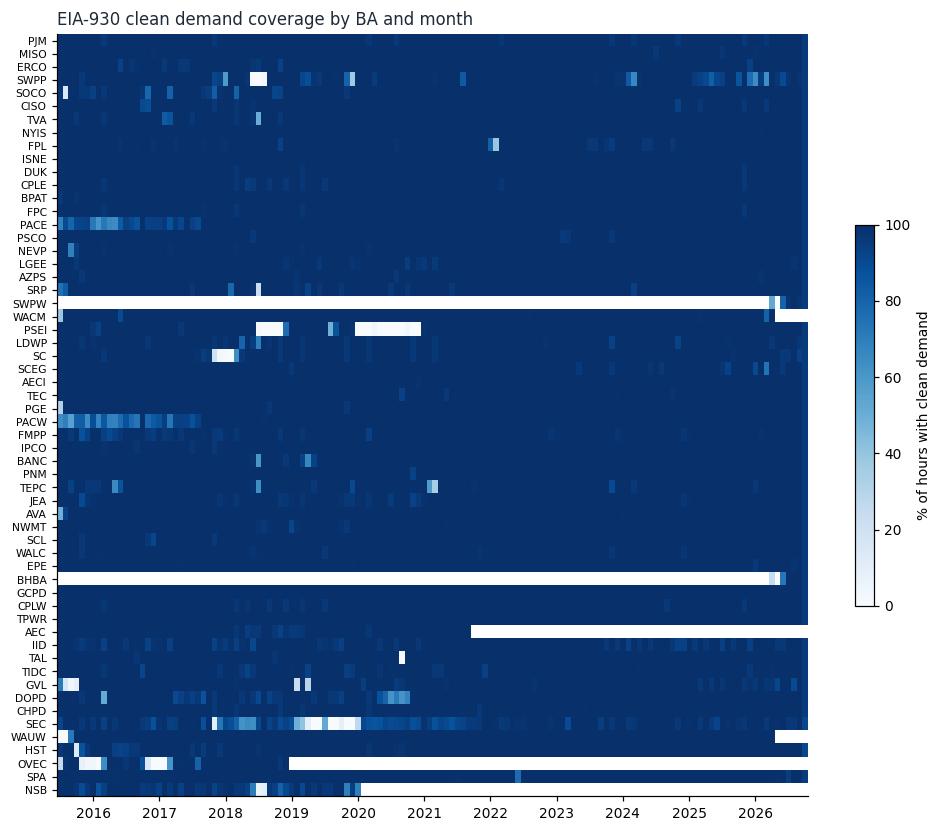

In [2]:
cov = (demand.group_by("ba", mo=pl.col("period_end_utc").dt.strftime("%Y-%m"))
       .agg(pct=pl.col("demand_clean").is_not_null().mean() * 100))
order = quality.sort("mean_mw", descending=True)["ba"].to_list()
grid = cov.pivot(on="mo", index="ba", values="pct", sort_columns=True)
grid = grid.join(pl.DataFrame({"ba": order, "rank": range(len(order))}), on="ba").sort("rank")
months = [c for c in grid.columns if c not in ("ba", "rank")]
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(grid.select(months).to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=100, interpolation="nearest")
ax.set_yticks(range(grid.height), grid["ba"].to_list(), fontsize=7)
ticks = [i for i, m in enumerate(months) if m.endswith("-01")]
ax.set_xticks(ticks, [months[i][:4] for i in ticks]); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.5, label="% of hours with clean demand")
ax.set_title("EIA-930 clean demand coverage by BA and month", loc="left", color=INK)
plt.show()

## 2. Flag counts per BA
Hours caught by each rule (one hour can trip several). EIA-imputed hours are those where EIA replaced or filled the reported value.

In [3]:
flags = ["flag_missing", "flag_negative", "flag_zero", "flag_flat_run", "flag_level_outlier", "flag_spike", "flag_eia_imputed"]
summary = demand.group_by("ba").agg(hours=pl.len(), *[pl.col(f).sum() for f in flags],
                                    flagged_pct=(pl.col("flag_any").mean() * 100).round(2)).sort("flagged_pct", descending=True)
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=200):
    display(summary)

ba,flag_missing,flag_negative,flag_zero,flag_flat_run,flag_level_outlier,flag_spike,flag_eia_imputed,hours,flagged_pct
str,u32,u32,u32,u32,u32,u32,u32,u32,f64
"""BHBA""",1512,0,0,0,0,0,24,4920,30.73
"""SWPW""",25,0,0,1246,0,0,1,4920,25.83
"""OVEC""",6708,0,14,297,32,24,182,29977,23.49
"""SEC""",749,8889,378,307,13220,1315,9555,99168,14.41
"""PSEI""",13200,0,0,0,1,1,292,99168,13.31
"""NSB""",2980,1,22,31,78,93,1160,39649,7.95
"""SWPP""",2508,0,0,2917,2,3,2461,99168,5.47
"""PACW""",3721,41,0,0,119,81,3628,99168,3.9
"""GVL""",3744,1,0,10,9,15,853,99168,3.8


## 3. What the rules catch: examples

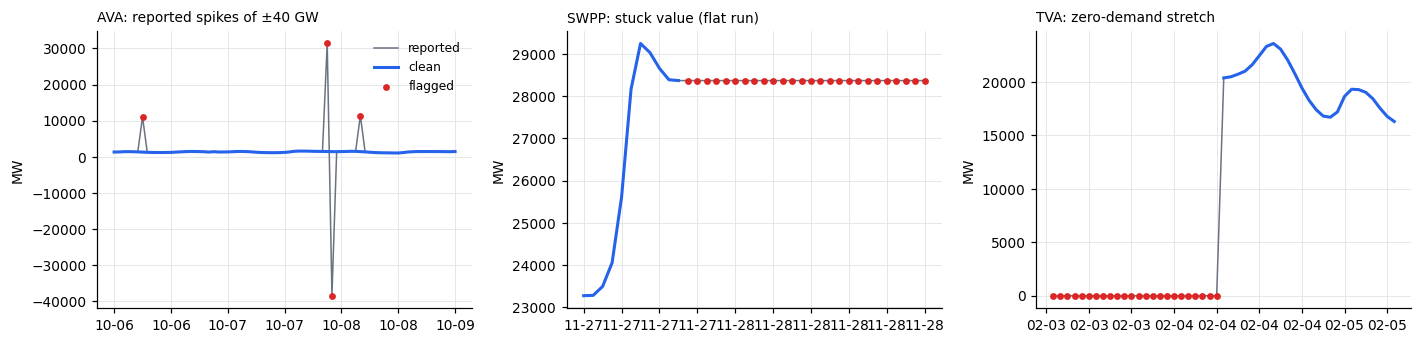

In [4]:
def window(ba, start, hours):
    return demand.filter((pl.col("ba") == ba) & pl.col("period_end_utc").is_between(start, start + timedelta(hours=hours)))

tva0 = demand.filter((pl.col("ba") == "TVA") & pl.col("flag_zero"))["period_end_utc"].min()
examples = [("AVA", datetime(2019, 10, 6, tzinfo=tva0.tzinfo), 72, "AVA: reported spikes of ±40 GW"),
            ("SWPP", datetime(2017, 11, 27, 8, tzinfo=tva0.tzinfo), 36, "SWPP: stuck value (flat run)"),
            ("TVA", tva0 - timedelta(hours=24), 72, "TVA: zero-demand stretch")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, (ba, start, hours, title) in zip(axes, examples):
    w = window(ba, start, hours)
    ax.plot(w["period_end_utc"], w["demand_raw"], color=MUTED, lw=1, label="reported")
    ax.plot(w["period_end_utc"], w["demand_clean"], color=ACCENT, lw=2, label="clean")
    bad = w.filter(pl.col("flag_any") & pl.col("demand_raw").is_not_null())
    ax.scatter(bad["period_end_utc"], bad["demand_raw"], color=ALERT, s=12, zorder=3, label="flagged")
    ax.set_title(title, loc="left", fontsize=9); ax.set_ylabel("MW")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 4. Level shifts (likely boundary or definition changes)
Median EIA-adjusted demand by year, indexed to 2019 = 100. A step that persists, not weather noise, points to a definition change. 2026 is a partial year (Jan–Oct), so it is biased toward summer.

In [5]:
yr = (demand.group_by("ba", y=pl.col("period_end_utc").dt.year()).agg(m=pl.col("demand_clean").median(), n=pl.col("demand_clean").is_not_null().sum())
      .filter(pl.col("n") > 6000))
idx = (yr.join(yr.filter(pl.col("y") == 2019).select("ba", b=pl.col("m")), on="ba")
         .with_columns(i=(pl.col("m") / pl.col("b") * 100).round(0)).pivot(on="y", index="ba", values="i", sort_columns=True))
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=200):
    display(idx.sort("2025", descending=True, nulls_last=True))

ba,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""WACM""",111.0,115.0,118.0,100.0,90.0,94.0,111.0,145.0,150.0,154.0,null
"""AZPS""",106.0,105.0,102.0,100.0,101.0,103.0,108.0,112.0,118.0,135.0,150.0
"""DOPD""",78.0,85.0,88.0,100.0,95.0,107.0,112.0,125.0,130.0,133.0,133.0
"""ERCO""",92.0,94.0,99.0,100.0,100.0,103.0,114.0,115.0,121.0,130.0,140.0
"""SC""",115.0,112.0,114.0,100.0,104.0,117.0,121.0,122.0,126.0,129.0,137.0
"""GCPD""",87.0,93.0,97.0,100.0,98.0,105.0,114.0,116.0,122.0,124.0,123.0
"""SRP""",98.0,99.0,98.0,100.0,103.0,105.0,107.0,110.0,114.0,120.0,127.0
"""TEPC""",121.0,121.0,108.0,100.0,107.0,105.0,109.0,117.0,118.0,118.0,127.0
"""FPL""",98.0,100.0,100.0,100.0,101.0,101.0,110.0,113.0,112.0,114.0,122.0


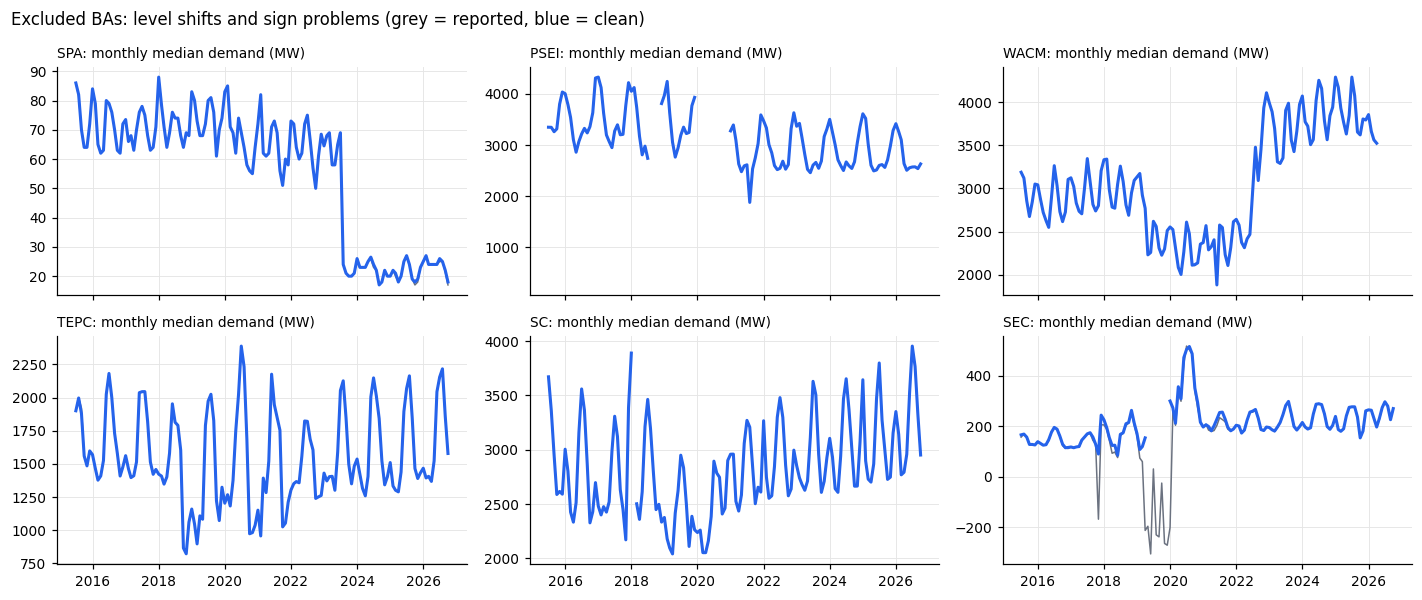

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True)
for ax, ba in zip(axes.flat, ["SPA", "PSEI", "WACM", "TEPC", "SC", "SEC"]):
    mo = (demand.filter(pl.col("ba") == ba).group_by(mo=pl.col("period_end_utc").dt.truncate("1mo"))
          .agg(raw=pl.col("demand_raw").median(), clean=pl.col("demand_clean").median()).sort("mo"))
    ax.plot(mo["mo"], mo["raw"], color=MUTED, lw=1); ax.plot(mo["mo"], mo["clean"], color=ACCENT, lw=2)
    ax.set_title(f"{ba}: monthly median demand (MW)", loc="left", fontsize=9)
plt.suptitle("Excluded BAs: level shifts and sign problems (grey = reported, blue = clean)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

## 5. Subregions: start dates and coverage
Subregion files begin 2018-07. Key finding: PJM zones (incl. DOM) are missing 2018-07-09 → 2018-09-18 and every November DST fall-back day in 2018, 2019 and 2023–2025.

In [7]:
subq = (sub.group_by("ba", "subregion").agg(first_clean=pl.col("period_end_utc").filter(pl.col("demand_clean").is_not_null()).min().dt.date(),
                                            mean_mw=pl.col("demand_clean").mean().round(0),
                                            clean_pct=(pl.col("demand_clean").is_not_null().mean() * 100).round(1))
          .sort("ba", "mean_mw", descending=[False, True]))
with pl.Config(tbl_rows=-1): display(subq)

ba,subregion,first_clean,mean_mw,clean_pct
str,str,date,f64,f64
"""BHBA""","""WYE""",2026-04-01,371.0,69.6
"""BHBA""","""SDE""",2026-04-01,311.0,69.6
"""BHBA""","""BASI""",2026-04-01,217.0,69.6
"""CISO""","""SCE""",2018-07-01,11974.0,99.8
"""CISO""","""PGAE""",2018-07-01,11311.0,99.0
"""CISO""","""SDGE""",2018-07-01,2155.0,99.8
"""CISO""","""VEA""",2018-07-01,76.0,95.6
"""ERCO""","""NCEN""",2019-05-27,14645.0,89.0
"""ERCO""","""COAS""",2019-05-27,13478.0,89.0


In [8]:
dom = sub.filter(pl.col("subregion") == "DOM")
gaps = (dom.with_columns(g=(pl.col("flag_any") != pl.col("flag_any").shift(1)).cum_sum()).filter(pl.col("flag_any"))
           .group_by("g").agg(start=pl.col("period_end_utc").min(), hours=pl.len()).filter(pl.col("hours") >= 24).sort("start").drop("g"))
print("DOM gaps of a day or more:"); display(gaps)
pre_covid = dom.filter(pl.col("period_end_utc") < pl.datetime(2020, 3, 1, time_zone="UTC"))["demand_clean"].is_not_null().sum()
print(f"DOM clean pre-COVID hours: {pre_covid:,} (~{pre_covid / 8766:.1f} years)")

DOM gaps of a day or more:


start,hours
"datetime[μs, UTC]",u32
2018-07-09 05:00:00 UTC,1704
2018-11-04 05:00:00 UTC,25
2019-11-03 05:00:00 UTC,25
2020-08-02 05:00:00 UTC,24
2022-11-05 05:00:00 UTC,24
2023-11-05 05:00:00 UTC,25
2024-11-03 05:00:00 UTC,25
2025-11-02 05:00:00 UTC,25
2026-10-21 05:00:00 UTC,24


DOM clean pre-COVID hours: 12,857 (~1.5 years)


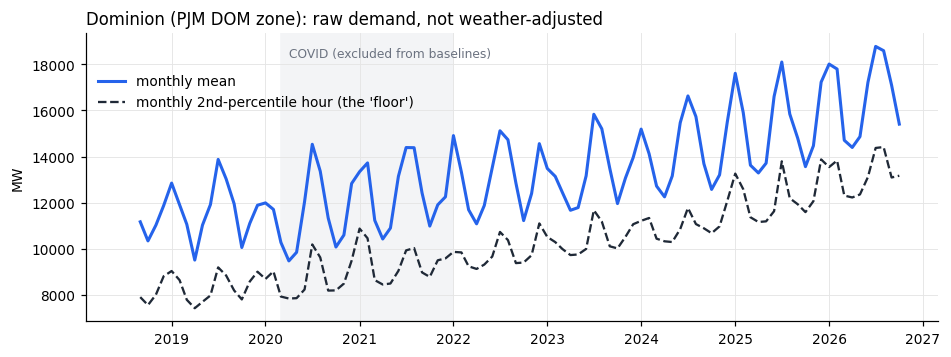

In [9]:
mo = (dom.group_by(mo=pl.col("period_end_utc").dt.truncate("1mo")).agg(mw=pl.col("demand_clean").mean(), floor=pl.col("demand_clean").quantile(0.02)).sort("mo"))
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(mo["mo"], mo["mw"], color=ACCENT, lw=2, label="monthly mean")
ax.plot(mo["mo"], mo["floor"], color=INK, lw=1.5, ls="--", label="monthly 2nd-percentile hour (the 'floor')")
ax.axvspan(datetime(2020, 3, 1), datetime(2021, 12, 31), color="#f3f4f6", zorder=0)
ax.text(datetime(2020, 4, 1), ax.get_ylim()[1] * 0.97, "COVID (excluded from baselines)", color=MUTED, fontsize=8, va="top")
ax.set_ylabel("MW"); ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.9))
ax.set_title("Dominion (PJM DOM zone): raw demand, not weather-adjusted", loc="left")
plt.show()

## 6. Modelling shortlist
Hand-curated in `data/reference/ba_shortlist.csv`, joined to the computed quality metrics.

In [10]:
with pl.Config(tbl_rows=-1, fmt_str_lengths=120, tbl_width_chars=220):
    display(shortlist.join(quality, left_on="series", right_on="ba", how="left").select("series", "role", "include", "mean_mw", "baseline_pct", "recent_pct", "min_year_pct", "reason"))

series,role,include,mean_mw,baseline_pct,recent_pct,min_year_pct,reason
str,str,str,f64,f64,f64,f64,str
"""PJM""","""focus""","""yes""",92195.0,99.9,99.7,99.5,"""Largest ISO; capacity-price story; contains Dominion. Clean coverage >99%"""
"""DOM""","""focus""","""conditional""",null,null,null,null,"""Dominion / Northern Virginia, the core data-center zone. EIA-930 subregion data usable only from 2018-09; needs PJM mete…"
"""ERCO""","""focus""","""yes""",47199.0,99.3,99.9,98.9,"""Texas; data centers plus crypto mining (known confounder). Clean coverage >98.9% every year"""
"""SOCO""","""focus""","""yes""",27062.0,97.5,100.0,96.0,"""Southern Co. incl. Georgia Power data-center growth. Min year 96%"""
"""AZPS""","""focus""","""yes""",3795.0,100.0,100.0,99.7,"""APS, Phoenix area data centers. Clean >99.7%"""
"""SRP""","""focus""","""yes""",3710.0,97.5,99.9,91.5,"""Salt River Project, Phoenix data centers. Min year 91.5% (check gap year in Prompt 3)"""
"""DUK""","""focus""","""yes""",12114.0,99.9,99.9,99.7,"""Duke Energy Carolinas; announced data-center load. Clean >99.7%"""
"""TVA""","""focus""","""yes""",18468.0,98.0,100.0,95.1,"""TVA; data-center announcements (Memphis, northern Alabama). Min year 95%"""
"""NEVP""","""focus""","""yes""",4442.0,99.9,100.0,99.9,"""NV Energy, Reno/Tahoe-Reno Industrial Center and Las Vegas data centers. Clean >99.9%"""
